In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Simulate 60 rows of results
np.random.seed(42)
n_rows = 60

all_metrics_df = pd.DataFrame({
    "learning_rate": np.random.choice([0.001, 0.003, 0.005], size=n_rows),
    "dropout_rate": np.random.choice([0.2, 0.3], size=n_rows),
    "batch_size": np.random.choice([32, 128], size=n_rows),
})

# Simulate accuracy for 10 tasks: test_1_accuracy to test_10_accuracy
for i in range(1, 11):
    all_metrics_df[f"test_{i}_accuracy"] = np.random.uniform(60, 100, size=n_rows)

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_accuracy_heatmaps_by_parameters(df, parameters, metric="accuracy", cmap="YlGnBu"):
    ncols = 2
    nrows = (len(parameters) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 5 * nrows))
    axes = axes.flatten()

    for i, param in enumerate(parameters):
        ax = axes[i]

        if df[param].dtype == "float64":
            df[param] = df[param].round(4)

        task_cols = [col for col in df.columns if col.startswith("test_") and col.endswith(f"_{metric}")]
        if not task_cols:
            ax.set_title(f"No test {metric} columns found", color='red')
            ax.axis("off")
            continue

        grouped = df[[param] + task_cols].groupby(param).mean()

        
        renamed = grouped.rename(columns={col: str(i+1) for i, col in enumerate(grouped.columns)})

        sns.heatmap(
            renamed,
            ax=ax,
            cmap=cmap,
            cbar=True,
            linewidths=0.4,
            linecolor="white",
            cbar_kws={"label": f"{metric.capitalize()} (%)"}
        )

        ax.set_title(f"Accuracy by {param.replace('_', ' ').title()}", fontsize=16, weight='bold', color='darkblue')
        ax.set_xlabel("Task", fontsize=14)
        ax.set_ylabel(param.replace("_", " ").title(), fontsize=14)
        ax.tick_params(axis='both', labelsize=12)

    for j in range(len(parameters), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

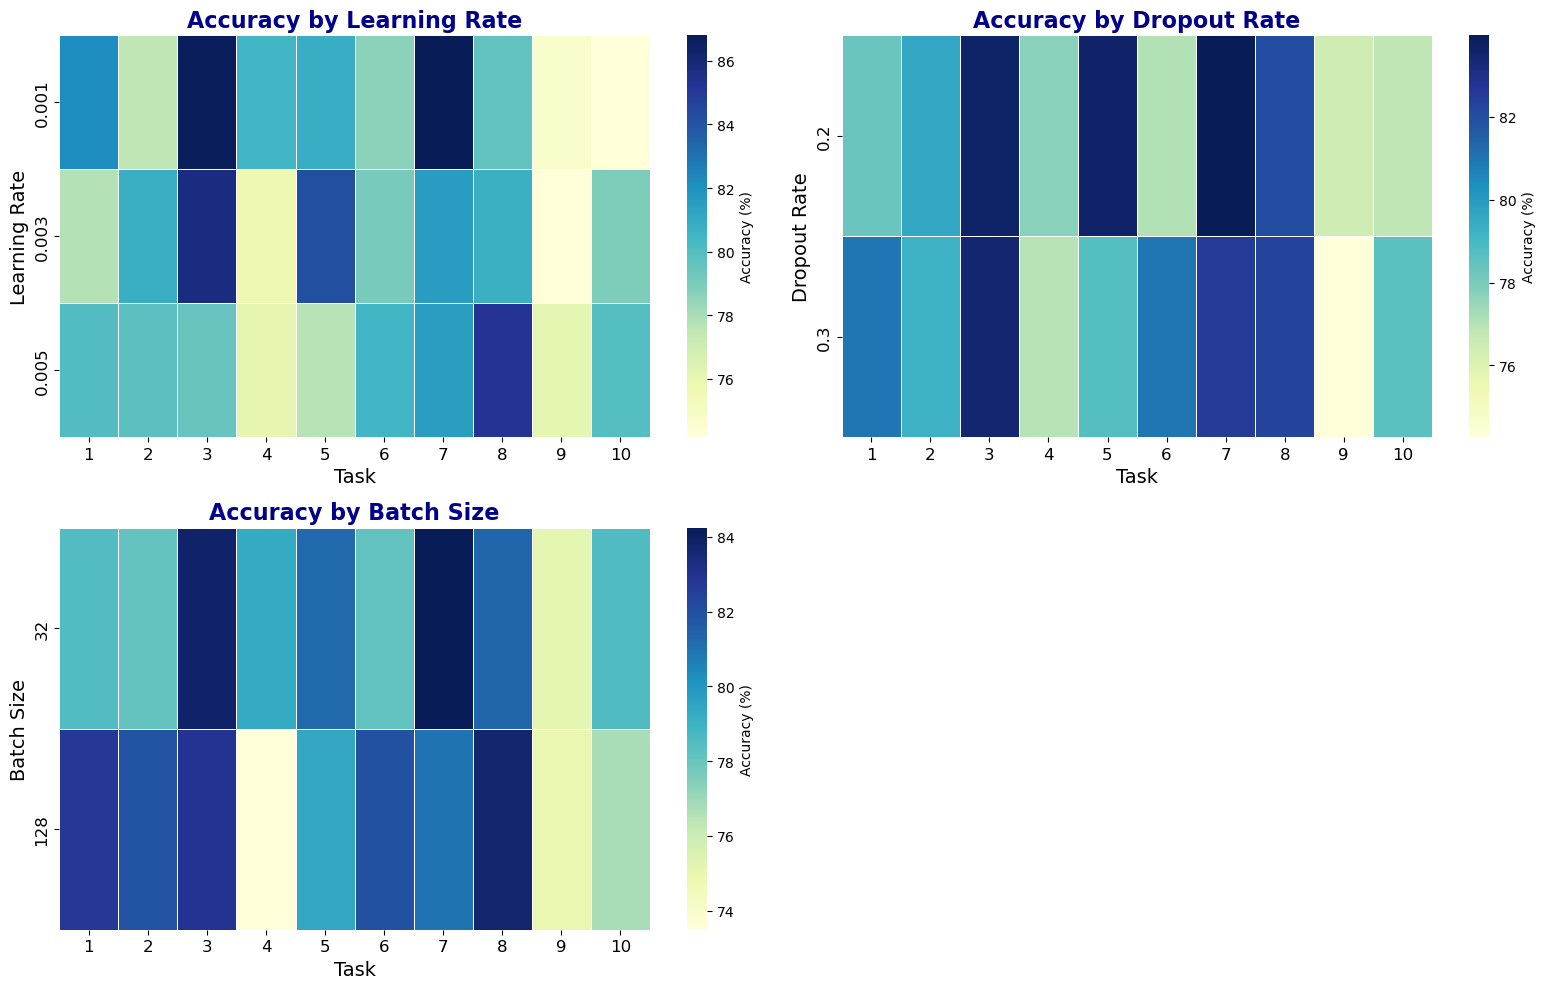

In [4]:
parameters_to_plot = ["learning_rate", "dropout_rate", "batch_size"]
plot_accuracy_heatmaps_by_parameters(all_metrics_df, parameters_to_plot, metric="accuracy")